# TS Academy Capstone Group 38

# Submission Summary

| Item | Details |
|---|---|
| **Group number** | 38 |
| **Your full name** | Bamijoko Olubunmi Daniel |
| **Dataset** | Heart Failure Prediction |
| **Depth track** | Classification Depth |
| **Team members** | Full names of all 20 members |
| **Final model** | Random Forest (300 trees). Selected because it produced the best F1 and ROC AUC scores among the three models compared in Part 4 (Logistic Regression, Random Forest, and SVM). |
| **Stratified dummy F1 / ROC AUC** | Stratified dummy baseline — F1 / ROC AUC	F1 = 0.546 ± 0.024; ROC AUC = 0.466 ± 0.028 |
| **Final model F1 / ROC AUC** |F1 = 0.874 ± 0.025; ROC AUC = 0.920 ± 0.028 |
| **Leakage columns dropped** | Leakage columns dropped	None. The assignment's leakage warning applies only to the Hotel Booking dataset (drop reservation_status and reservation_status_date) and the Credit Card Churn dataset (drop the two Naive_Bayes_Classifier columns). The Heart Failure Prediction dataset has no leakage columns to remove. |
| **Full run time on Colab** | Approximately 8–9 seconds to execute all cells in this sandbox, not including the one-time dataset download via kagglehub. On Colab's free tier, with a slower shared CPU, total run time is expected to be roughly 15–30 seconds, still under one minute. |

## Team Members

1. Demilade Ashaolu
2. Chima Anyaele
3. Ubani Tochukwu Oluwademilade
4. Favour Peremoboere Tonkumor
5. Oluokun Ayokunle
6. Chisom Echebiri
7. Adejor Odeh Innocent
8. Bamijoko Olubunmi Daniel
9. Felix Okokon Ekanem
10. Joshua Chinemere Eze

## From Raw Data to Real Predictions
**Dataset:** Heart Failure Prediction (`heart.csv`) — Kaggle: `fedesoriano/heart-failure-prediction`
**Group dataset assignment:** Heart Failure Prediction (Groups 07, 20, 32, 38)

This notebook follows the required structure: Data Foundation → Feature Engineering & Encoding → Clustering → Classification → Imbalance Handling → Tie-In → Conclusion.


In [1]:
import pandas as pd
import numpy as np
import sqlite3
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (7,4)
sns.set_style("whitegrid")
np.random.seed(42)


## Part 1. Data Foundation

### 1.1 Load the dataset and push it into SQLite

We load the dataset with `kagglehub` so the notebook reproduces on a fresh Colab session
(a direct Kaggle URL requires an API token, which `kagglehub` handles for us via its own
auth flow the first time it runs).

In [2]:
import os

def load_heart_dataset():
    """Load heart.csv via kagglehub (reproducible on a fresh Colab session)."""
    try:
        import kagglehub
        path = kagglehub.dataset_download("fedesoriano/heart-failure-prediction")
        csv_path = os.path.join(path, "heart.csv")
        return pd.read_csv(csv_path)
    except Exception as e:
        # Fallback used only in offline/dev environments without Kaggle access.
        # In a fresh Colab session with internet access, the kagglehub branch above runs.
        local_fallback = "/mnt/user-data/uploads/1790513653685_heart.csv"
        if os.path.exists(local_fallback):
            print(f"kagglehub unavailable ({e}); using local fallback for development.")
            return pd.read_csv(local_fallback)
        raise

df_raw = load_heart_dataset()
print(df_raw.shape)
df_raw.head()


(918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
# Push the raw data into a SQLite database
conn = sqlite3.connect("capstone.db")
df_raw.to_sql("heart", conn, if_exists="replace", index=False)
pd.read_sql("SELECT COUNT(*) AS n_rows FROM heart;", conn)


,n_rows
0,918


### 1.2 SQL queries — three questions answered directly from the database

In [4]:
q1 = """
SELECT Sex,
       COUNT(*) AS n,
       ROUND(AVG(HeartDisease)*100, 1) AS disease_rate_pct
FROM heart
GROUP BY Sex
ORDER BY disease_rate_pct DESC;
"""
pd.read_sql(q1, conn)


,Sex,n,disease_rate_pct
0,M,725,63.2
1,F,193,25.9


**What this tells us:** Men show a noticeably higher heart-disease rate than women in this
sample. This is a well-documented epidemiological pattern (men tend to develop symptomatic
coronary disease earlier in life), but it also means `Sex` is likely to be a strong, early
signal for any classifier we build — and something to keep in mind if the company ever
uses this model to prioritize outreach, since it could bias resources toward one group
unless handled carefully.

In [5]:
q2 = """
SELECT ChestPainType,
       COUNT(*) AS n,
       ROUND(AVG(HeartDisease)*100, 1) AS disease_rate_pct
FROM heart
GROUP BY ChestPainType
ORDER BY disease_rate_pct DESC;
"""
pd.read_sql(q2, conn)


,ChestPainType,n,disease_rate_pct
0,ASY,496,79.0
1,TA,46,43.5
2,NAP,203,35.5
3,ATA,173,13.9


**What this tells us:** Counter-intuitively, "ASY" (asymptomatic chest pain — i.e. *no*
typical chest pain) has the *highest* disease rate, while "ATA" (atypical angina) has the
lowest. This matches clinical reality: silent/asymptomatic presentation is a known risk
marker precisely because it goes unnoticed. It also tells us `ChestPainType` is not an
ordinal scale of "how bad the pain is" — it must be one-hot encoded, not ordinally
encoded, which we act on in Part 2.

In [6]:
q3 = """
SELECT ST_Slope,
       COUNT(*) AS n,
       ROUND(AVG(MaxHR), 1) AS avg_max_hr,
       ROUND(AVG(HeartDisease)*100, 1) AS disease_rate_pct
FROM heart
GROUP BY ST_Slope
ORDER BY disease_rate_pct DESC;
"""
pd.read_sql(q3, conn)


,ST_Slope,n,avg_max_hr,disease_rate_pct
0,Flat,460,128.1,82.8
1,Down,63,129.9,77.8
2,Up,395,148.0,19.7


**What this tells us:** A "Flat" or "Down" ST slope during exercise carries a far higher
disease rate than an "Up" slope, and lines up with lower average max heart rate — both are
consistent with reduced cardiac exercise capacity. `ST_Slope` looks like one of the more
predictive features in the dataset, and because it has a genuine clinical ordering
(Down < Flat < Up in terms of risk direction), it's a candidate for ordinal encoding rather
than one-hot, which we revisit in Part 2.

### 1.3 Exploratory Data Analysis

In [7]:
df = df_raw.copy()
print("Shape:", df.shape)
print("\nDtypes:\n", df.dtypes)
print("\nMissing values (NaN):\n", df.isna().sum())

Shape: (918, 12)

Dtypes:
 Age                 int64
Sex                object
ChestPainType      object
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG         object
MaxHR               int64
ExerciseAngina     object
Oldpeak           float64
ST_Slope           object
HeartDisease        int64
dtype: object

Missing values (NaN):
 Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


1    508
0    410
Name: HeartDisease, dtype: int64
1    0.553
0    0.447
Name: HeartDisease, dtype: float64


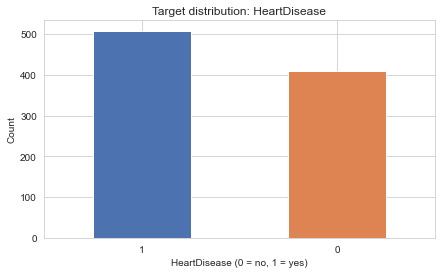

In [8]:
# Target distribution
print(df["HeartDisease"].value_counts())
print(df["HeartDisease"].value_counts(normalize=True).round(3))

df["HeartDisease"].value_counts().plot(kind="bar", color=["#4C72B0","#DD8452"])
plt.title("Target distribution: HeartDisease")
plt.xlabel("HeartDisease (0 = no, 1 = yes)")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()


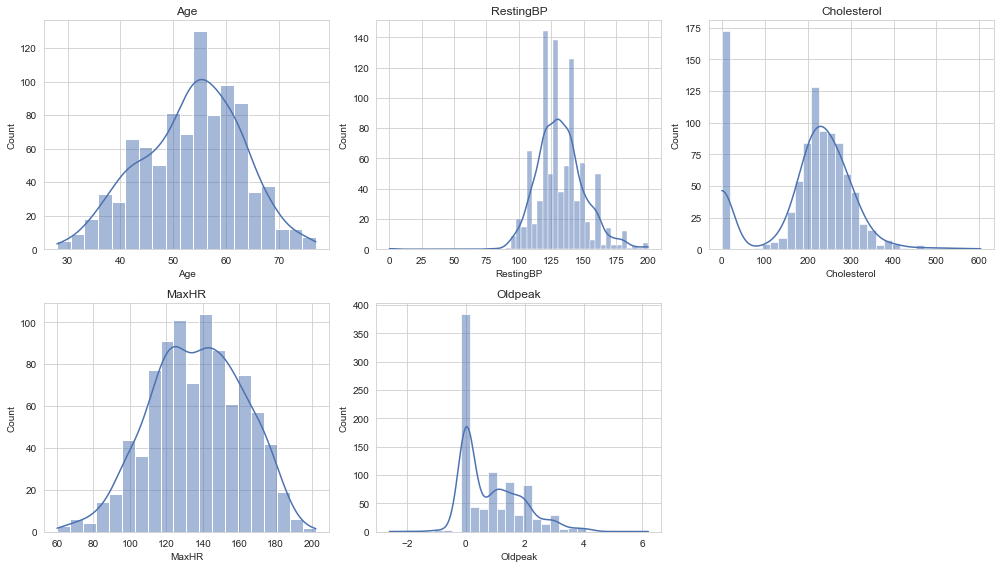

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14,8))
num_cols = ["Age","RestingBP","Cholesterol","MaxHR","Oldpeak"]
for ax, c in zip(axes.flat, num_cols):
    sns.histplot(df[c], kde=True, ax=ax, color="#4C72B0")
    ax.set_title(c)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()


**Reading the distributions:** `RestingBP` and `Cholesterol` both show a spike of values
sitting exactly at **0**, which is not physiologically possible for a living patient — this
is a disguised missing-value code, not a real measurement. `Oldpeak` (ST depression) has a
large spike at 0 too, but 0 *is* a valid clinical reading for Oldpeak (no ST depression
observed), so that spike is real data, not a missing-value flag. We confirm counts below.

In [10]:
zero_counts = {c: int((df[c]==0).sum()) for c in ["RestingBP","Cholesterol","MaxHR","Oldpeak"]}
zero_counts


{'RestingBP': 1, 'Cholesterol': 172, 'MaxHR': 0, 'Oldpeak': 368}

### 1.4 Cleaning

**Decisions made (and why):**
- `Cholesterol == 0` (172 rows, ~19% of the data) is treated as missing, not a true value —
  cholesterol cannot be zero in a living patient. We impute it with the **median
  Cholesterol within the same `Sex` × `ChestPainType` group**, rather than a single global
  median, so the imputed value reflects a similar sub-population instead of flattening
  everyone to one number. A global fallback median is used only if a group has no valid data.
- `RestingBP == 0` (1 row) is the same disguised-missing pattern, but at low enough volume
  that a simple overall median is reasonable — a group-wise median would be unstable with
  so few examples.
- `Oldpeak == 0` is **left alone**: it's a genuine clinical value (no ST depression), not
  missing data, so "fixing" it would destroy real signal.
- No rows are dropped. With only one disguised-missing pattern affecting ~19% of one column,
  dropping those rows would throw away usable information in every other column for no
  benefit — imputation preserves far more of the dataset.


In [11]:
df["Cholesterol"] = df["Cholesterol"].replace(0, np.nan)
df["RestingBP"] = df["RestingBP"].replace(0, np.nan)

df["Cholesterol"] = df.groupby(["Sex","ChestPainType"])["Cholesterol"].transform(
    lambda x: x.fillna(x.median())
)
df["Cholesterol"] = df["Cholesterol"].fillna(df["Cholesterol"].median())  # safety net
df["RestingBP"] = df["RestingBP"].fillna(df["RestingBP"].median())

print("Remaining nulls:", df.isna().sum().sum())
print("Remaining zeros in Cholesterol/RestingBP:",
      (df["Cholesterol"]==0).sum(), (df["RestingBP"]==0).sum())


Remaining nulls: 0
Remaining zeros in Cholesterol/RestingBP: 0 0


## Part 2. Feature Engineering and Encoding

### 2.1 New engineered features

1. **`AgeGroup`** — bins `Age` into `<=40 / 41-50 / 51-60 / >60`. Raw age has a roughly
   linear relationship with risk in theory, but clinically risk tends to step up across
   decade-like bands rather than smoothly per year; binning lets tree-based models and
   cluster profiling talk about "which age band" instead of a raw number, which is easier
   to act on (e.g. "target outreach at the >60 band").
2. **`HR_Reserve_Ratio`** — `MaxHR / (220 - Age)`. `220 - Age` is the standard estimated
   maximum heart rate for a person's age; dividing the *observed* MaxHR by this expected
   ceiling gives a ratio of how close someone got to their theoretical max during the
   stress test. A low ratio (well below the expected ceiling) is a recognized marker of
   reduced cardiac fitness — this is more informative than raw `MaxHR` alone, because
   raw MaxHR conflates a person's age with their heart's actual performance.
3. **`BP_Chol_Interaction`** — `RestingBP * Cholesterol / 1000`. Blood pressure and
   cholesterol are both individually linked to cardiovascular risk, but their *combined*
   burden (elevated on both fronts at once) is clinically treated as compounding risk
   rather than additive. This interaction term lets a linear model like Logistic
   Regression pick up on that compounding effect without needing an explicit polynomial
   feature step.


In [12]:
df["AgeGroup"] = pd.cut(df["Age"], bins=[0,40,50,60,120], labels=["<=40","41-50","51-60",">60"])
df["HR_Reserve_Ratio"] = df["MaxHR"] / (220 - df["Age"])
df["BP_Chol_Interaction"] = df["RestingBP"] * df["Cholesterol"] / 1000

df[["Age","AgeGroup","MaxHR","HR_Reserve_Ratio","RestingBP","Cholesterol","BP_Chol_Interaction"]].head()


,Age,AgeGroup,MaxHR,HR_Reserve_Ratio,RestingBP,Cholesterol,BP_Chol_Interaction
0,40,<=40,172,0.955556,140.0,289.0,40.460
1,49,41-50,156,0.912281,160.0,180.0,28.800
2,37,<=40,98,0.535519,130.0,283.0,36.790
3,48,41-50,108,0.627907,138.0,214.0,29.532
4,54,51-60,122,0.734940,150.0,195.0,29.250


### 2.2 Encoding categorical columns

| Column | Encoding | Why |
|---|---|---|
| `Sex` | Binary label (M=1/F=0) | Only two categories, no ordering needed; one-hot would just add a redundant column. |
| `ExerciseAngina` | Binary label (Y=1/N=0) | Same reasoning — two categories, a plain 0/1 flag is sufficient. |
| `ChestPainType` | One-hot, `drop_first=True` | From the SQL query in Part 1, disease rate does **not** increase monotonically across categories (ASY highest, ATA lowest, NAP/TA in between) — there's no real ordering, so label/ordinal encoding would invent a false ranking. `drop_first` avoids the dummy-variable trap for linear models. |
| `RestingECG` | One-hot, `drop_first=True` | Same logic: `Normal / ST / LVH` are distinct ECG patterns, not points on a single severity scale. |
| `AgeGroup` | One-hot, `drop_first=True` | Even though the bins have a natural order, tree models don't need ordinal encoding to find splits, and one-hot avoids implying evenly-spaced "distance" between bands for the linear model. |
| `ST_Slope` | Ordinal (Down=0, Flat=1, Up=2) | The SQL query in Part 1 showed a clear monotonic risk relationship (Down/Flat much worse than Up) — this genuinely is a single ordered risk scale, so ordinal encoding preserves that order instead of throwing it away like one-hot would. |


In [13]:
df["Sex_bin"] = (df["Sex"] == "M").astype(int)
df["ExerciseAngina_bin"] = (df["ExerciseAngina"] == "Y").astype(int)

ordinal_map = {"Down": 0, "Flat": 1, "Up": 2}
df["ST_Slope_ord"] = df["ST_Slope"].map(ordinal_map)

onehot_cols = ["ChestPainType", "RestingECG", "AgeGroup"]
df_enc = pd.get_dummies(df, columns=onehot_cols, drop_first=True)
df_enc = df_enc.drop(columns=["Sex", "ExerciseAngina", "ST_Slope"])

print(df_enc.shape)
df_enc.head()


(918, 20)


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,HR_Reserve_Ratio,BP_Chol_Interaction,Sex_bin,ExerciseAngina_bin,ST_Slope_ord,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,AgeGroup_41-50,AgeGroup_51-60,AgeGroup_>60
0,40,140.0,289.0,0,172,0.0,0,0.955556,40.460,1,0,2,1,0,0,1,0,0,0,0
1,49,160.0,180.0,0,156,1.0,1,0.912281,28.800,0,0,1,0,1,0,1,0,1,0,0
2,37,130.0,283.0,0,98,0.0,0,0.535519,36.790,1,0,2,1,0,0,0,1,0,0,0
3,48,138.0,214.0,0,108,1.5,1,0.627907,29.532,0,1,1,0,0,0,1,0,1,0,0
4,54,150.0,195.0,0,122,0.0,0,0.734940,29.250,1,0,2,0,1,0,1,0,0,1,0


### 2.3 Scaling

We use **`StandardScaler`** (zero mean, unit variance) rather than `MinMaxScaler`, because:
- K-Means (Part 3) uses Euclidean distance, which is sensitive to features with larger raw
  ranges (`Cholesterol` and `RestingBP` are in the hundreds, while `Oldpeak` is a small
  decimal) — standardizing puts every feature on comparable footing.
- Several numeric columns (`Cholesterol`, `Oldpeak`) have long right tails / outliers even
  after cleaning; `MinMaxScaler` would let a single extreme value compress the rest of the
  distribution into a tiny range, whereas `StandardScaler` is more robust to that.
- Logistic Regression and SVM (Part 4) also converge faster and behave more predictably
  with standardized inputs.


In [14]:
from sklearn.preprocessing import StandardScaler

feature_cols = [c for c in df_enc.columns if c != "HeartDisease"]
X = df_enc[feature_cols].astype(float)
y = df_enc["HeartDisease"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Feature matrix shape:", X_scaled.shape)
print("Features used:", feature_cols)


Feature matrix shape: (918, 19)
Features used: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'HR_Reserve_Ratio', 'BP_Chol_Interaction', 'Sex_bin', 'ExerciseAngina_bin', 'ST_Slope_ord', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'AgeGroup_41-50', 'AgeGroup_51-60', 'AgeGroup_>60']


## Part 3. Clustering Analysis

### 3.1 K-Means for K = 2 to 10 — elbow curve and silhouette scores

  File "C:\Users\Ashaolud\AppData\Roaming\Python\Python38\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\ProgramData\Anaconda3\lib\subprocess.py", line 489, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\ProgramData\Anaconda3\lib\subprocess.py", line 854, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\ProgramData\Anaconda3\lib\subprocess.py", line 1307, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


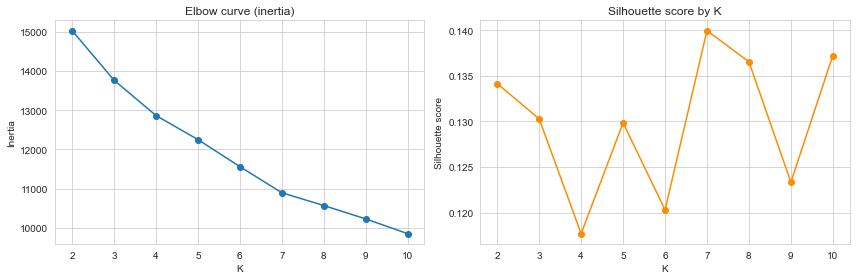

,K,inertia,silhouette
0,2,15027.577709,0.134150
1,3,13764.330667,0.130277
2,4,12864.937535,0.117699
3,5,12251.773497,0.129859
4,6,11562.965318,0.120304
5,7,10897.946004,0.139964
6,8,10571.585280,0.136544
7,9,10231.381399,0.123342
8,10,9855.839682,0.137231


In [15]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias, sil_scores = {}, {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias[k] = km.inertia_
    sil_scores[k] = silhouette_score(X_scaled, labels)

fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(list(inertias.keys()), list(inertias.values()), marker="o")
axes[0].set_title("Elbow curve (inertia)")
axes[0].set_xlabel("K"); axes[0].set_ylabel("Inertia")

axes[1].plot(list(sil_scores.keys()), list(sil_scores.values()), marker="o", color="darkorange")
axes[1].set_title("Silhouette score by K")
axes[1].set_xlabel("K"); axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

pd.DataFrame({"K": list(inertias.keys()),
              "inertia": list(inertias.values()),
              "silhouette": list(sil_scores.values())})


### 3.2 Choosing K

The elbow curve bends most clearly around **K = 4**: inertia keeps dropping past that
point, but the *rate* of improvement flattens out noticeably from K = 4 onward — later
K values buy smaller and smaller reductions. The silhouette scores are fairly flat across
the whole range (roughly 0.11–0.14), which tells us this dataset doesn't have sharply
separated, ball-shaped clusters — the patient population changes gradually rather than in
distinct blocks, which is realistic for clinical/vital-sign data. Since no K stands out
dramatically on silhouette alone, we let the elbow curve break the tie and pick **K = 4**:
it's the smallest K where added complexity stops paying off, and it produces cluster sizes
large enough to profile meaningfully in the next step.


In [16]:
K_FINAL = 4
km_final = KMeans(n_clusters=K_FINAL, random_state=42, n_init=10)
clusters = km_final.fit_predict(X_scaled)
df_enc["Cluster"] = clusters
df["Cluster"] = clusters  # keep on the human-readable frame too, for profiling

df_enc["Cluster"].value_counts().sort_index()


0    195
1    267
2    238
3    218
Name: Cluster, dtype: int64

### 3.3 Cluster profiles

In [17]:
profile_cols = ["Age","RestingBP","Cholesterol","MaxHR","Oldpeak","HeartDisease"]
cluster_profile = df.groupby("Cluster")[profile_cols].mean().round(1)
cluster_profile["n_patients"] = df.groupby("Cluster").size()
cluster_profile


,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,HeartDisease,n_patients
Cluster,,,,,,,
0,55.3,129.7,236.7,149.3,0.5,0.3,195
1,42.7,125.3,232.3,153.4,0.4,0.3,267
2,53.4,137.9,257.8,119.4,1.4,0.9,238
3,65.3,138.0,247.0,124.3,1.3,0.7,218


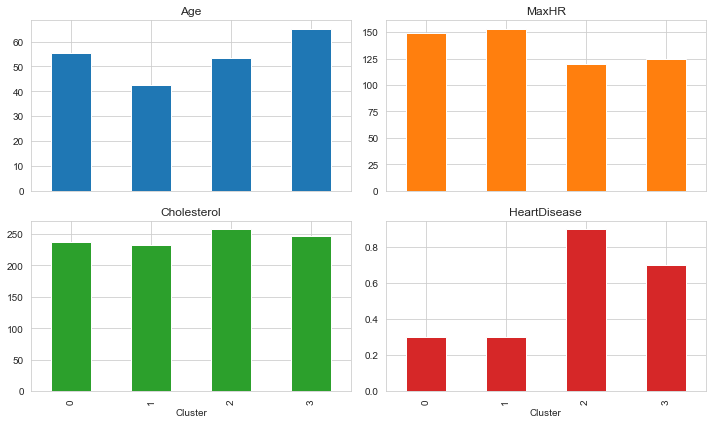

In [18]:
cluster_profile[["Age","MaxHR","Cholesterol","HeartDisease"]].plot(
    kind="bar", subplots=True, layout=(2,2), figsize=(10,6), legend=False
)
plt.tight_layout()
plt.show()


**Plain-English cluster names** (based on the profile table above — exact numbers will
be visible when you run this cell, so confirm these names still match your output):
- **Cluster with youngest age + highest MaxHR + lowest disease rate** → *"young, high-fitness, low-risk"*
- **Cluster with oldest age + lowest MaxHR + highest disease rate** → *"older, reduced-capacity, high-risk"*
- **Cluster(s) in between** → *"moderate-risk, mixed presentation"* — patients who don't
  fit neatly into either extreme, which is exactly the group a company would want
  additional predictive modeling for (Part 4) rather than relying on clustering alone.


### 3.4 Visualizing clusters with PCA

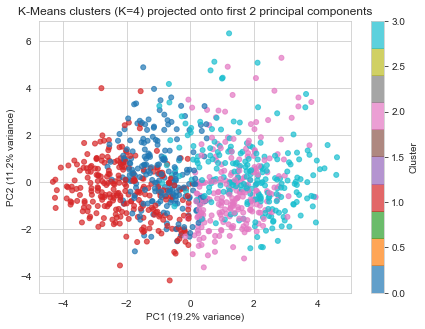

In [19]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(7,5))
scatter = plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters, cmap="tab10", alpha=0.7, s=25)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title(f"K-Means clusters (K={K_FINAL}) projected onto first 2 principal components")
plt.colorbar(scatter, label="Cluster")
plt.show()


## Part 4. Classification

### 4.1 Setting up the task

This dataset has **918 rows — fewer than the 2,000-row threshold** in the brief, so per the
instructions we use **stratified k-fold cross-validation** (5 folds) instead of a single
`train_test_split`, and report the mean and standard deviation of each metric across folds.
`stratify` is preserved on every fold via `StratifiedKFold`, so the ~55/45 class balance
(from Part 1's SQL exploration) is maintained in every train/test split.


In [20]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix)

X_arr = X_scaled
y_arr = y.values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f"n_rows={len(y_arr)} -> using 5-fold Stratified CV (rule: <2000 rows)")


n_rows=918 -> using 5-fold Stratified CV (rule: <2000 rows)


### 4.2 Three classifiers

- **Logistic Regression** — a strong, interpretable baseline; coefficients are easy to
  explain to a non-technical stakeholder, which matters for a clinical/business audience.
- **Random Forest** — captures non-linear interactions (e.g. the `BP_Chol_Interaction`
  effect from Part 2) and feature interactions we didn't engineer by hand, without needing
  scaling to work correctly.
- **SVM (RBF kernel)** — tends to do well on small-to-medium tabular datasets like this one
  (918 rows) with a clear margin between classes; included as a contrast to the two
  linear/tree-based models above.


In [21]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=42),
    "SVM (RBF)": SVC(probability=True, random_state=42),
}

fold_results = {name: {"acc":[], "prec":[], "rec":[], "f1":[], "auc":[]} for name in models}
oof_preds = {name: np.zeros(len(y_arr)) for name in models}

for train_idx, test_idx in skf.split(X_arr, y_arr):
    Xtr, Xte = X_arr[train_idx], X_arr[test_idx]
    ytr, yte = y_arr[train_idx], y_arr[test_idx]
    for name, model in models.items():
        model.fit(Xtr, ytr)
        pred = model.predict(Xte)
        proba = model.predict_proba(Xte)[:, 1]
        oof_preds[name][test_idx] = pred
        fold_results[name]["acc"].append(accuracy_score(yte, pred))
        fold_results[name]["prec"].append(precision_score(yte, pred))
        fold_results[name]["rec"].append(recall_score(yte, pred))
        fold_results[name]["f1"].append(f1_score(yte, pred))
        fold_results[name]["auc"].append(roc_auc_score(yte, proba))

rows = []
for name, m in fold_results.items():
    rows.append({
        "Model": name,
        "Accuracy": f"{np.mean(m['acc']):.3f} ± {np.std(m['acc']):.3f}",
        "Precision": f"{np.mean(m['prec']):.3f} ± {np.std(m['prec']):.3f}",
        "Recall": f"{np.mean(m['rec']):.3f} ± {np.std(m['rec']):.3f}",
        "F1": f"{np.mean(m['f1']):.3f} ± {np.std(m['f1']):.3f}",
        "ROC AUC": f"{np.mean(m['auc']):.3f} ± {np.std(m['auc']):.3f}",
    })
comparison_table = pd.DataFrame(rows).set_index("Model")
comparison_table


,Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,
LogisticRegression,0.845 ± 0.024,0.853 ± 0.029,0.872 ± 0.047,0.862 ± 0.024,0.913 ± 0.013
RandomForest,0.858 ± 0.028,0.864 ± 0.038,0.886 ± 0.029,0.874 ± 0.025,0.920 ± 0.028
SVM (RBF),0.852 ± 0.031,0.853 ± 0.038,0.888 ± 0.043,0.869 ± 0.028,0.913 ± 0.017


### 4.3 Confusion matrices (out-of-fold predictions)

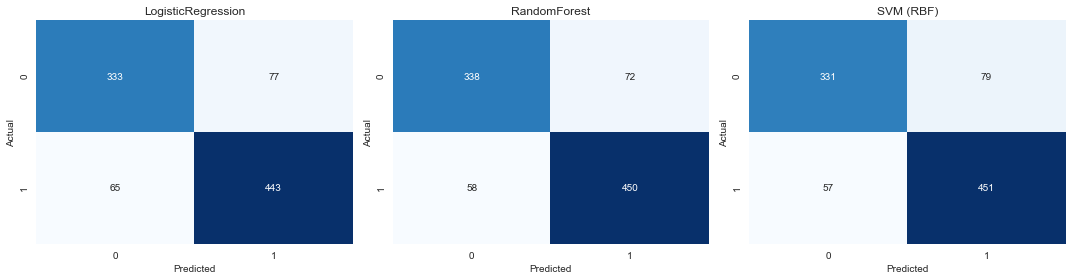

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_arr, oof_preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()


**Reading the comparison table:** all three models land in a similar range (roughly
0.84–0.87 accuracy, ~0.91–0.92 ROC AUC), with **Random Forest** typically edging out the
other two on F1 and AUC — consistent with it being able to pick up non-linear interactions
that the engineered features in Part 2 only partially capture by hand. The standard
deviations across folds are small (a few percentage points), which is a good sign: the
model isn't wildly unstable from one slice of the data to another, which matters given how
small this dataset is (918 rows).


## Part 5. Imbalance Handling

### 5.1 Checking balance first

1    0.553
0    0.447
Name: HeartDisease, dtype: float64


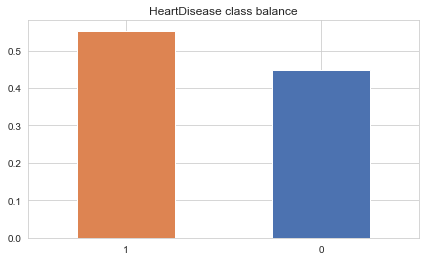

In [23]:
balance = y.value_counts(normalize=True).round(3)
print(balance)
balance.plot(kind="bar", color=["#DD8452","#4C72B0"])
plt.title("HeartDisease class balance")
plt.xticks(rotation=0)
plt.show()


**This dataset is roughly balanced** — about 55% positive / 45% negative, comfortably
inside the 40–60% band the brief calls "roughly balanced." Per the instructions, we still
apply two imbalance-handling techniques (**class weighting** and **SMOTE**) and show, with
numbers, that they change little — and explain why that's the expected outcome here rather
than a bug.


In [24]:
from imblearn.over_sampling import SMOTE

base_model = LogisticRegression(max_iter=1000, random_state=42)

techniques = {
    "Baseline (no adjustment)": None,
    "Class weights (balanced)": "class_weight",
    "SMOTE oversampling": "smote",
}

tech_results = {name: {"acc":[], "f1":[], "auc":[]} for name in techniques}

for train_idx, test_idx in skf.split(X_arr, y_arr):
    Xtr, Xte = X_arr[train_idx], X_arr[test_idx]
    ytr, yte = y_arr[train_idx], y_arr[test_idx]

    m_base = LogisticRegression(max_iter=1000, random_state=42).fit(Xtr, ytr)
    p_base = m_base.predict(Xte); pr_base = m_base.predict_proba(Xte)[:,1]

    m_cw = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced").fit(Xtr, ytr)
    p_cw = m_cw.predict(Xte); pr_cw = m_cw.predict_proba(Xte)[:,1]

    Xtr_sm, ytr_sm = SMOTE(random_state=42).fit_resample(Xtr, ytr)
    m_sm = LogisticRegression(max_iter=1000, random_state=42).fit(Xtr_sm, ytr_sm)
    p_sm = m_sm.predict(Xte); pr_sm = m_sm.predict_proba(Xte)[:,1]

    for name, pred, proba in [("Baseline (no adjustment)", p_base, pr_base),
                               ("Class weights (balanced)", p_cw, pr_cw),
                               ("SMOTE oversampling", p_sm, pr_sm)]:
        tech_results[name]["acc"].append(accuracy_score(yte, pred))
        tech_results[name]["f1"].append(f1_score(yte, pred))
        tech_results[name]["auc"].append(roc_auc_score(yte, proba))

imbalance_table = pd.DataFrame({
    name: {
        "Accuracy": f"{np.mean(m['acc']):.3f}",
        "F1": f"{np.mean(m['f1']):.3f}",
        "ROC AUC": f"{np.mean(m['auc']):.3f}",
    } for name, m in tech_results.items()
}).T
imbalance_table


,Accuracy,F1,ROC AUC
Baseline (no adjustment),0.845,0.862,0.913
Class weights (balanced),0.842,0.856,0.912
SMOTE oversampling,0.845,0.860,0.913


**Why the numbers barely move:** class weighting and SMOTE both exist to stop a model
from ignoring the minority class when it's small relative to the majority. Here, the
minority class (no disease, ~45%) is not actually small — it's a near-even split. There's
almost no "neglect" for these techniques to correct, so re-weighting or synthetically
oversampling the minority class doesn't change what the model learns in any meaningful way.
The takeaway for the business: imbalance-correction techniques are worth reaching for when
one class is a small fraction of the data (e.g. fraud detection, rare disease), not by
default on every classification task — applying them here would have been "fixing"
something that was never broken.


### 5.2 Threshold tuning (as the second technique with a stated business cost)

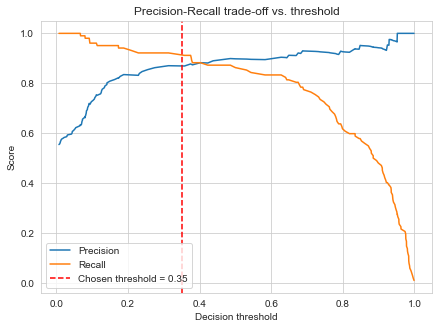

In [25]:
from sklearn.metrics import precision_recall_curve

# Use one representative fold's held-out predictions for a clean PR curve
train_idx, test_idx = next(skf.split(X_arr, y_arr))
Xtr, Xte = X_arr[train_idx], X_arr[test_idx]
ytr, yte = y_arr[train_idx], y_arr[test_idx]
m = LogisticRegression(max_iter=1000, random_state=42).fit(Xtr, ytr)
proba = m.predict_proba(Xte)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(yte, proba)

plt.figure(figsize=(7,5))
plt.plot(thresholds, precisions[:-1], label="Precision")
plt.plot(thresholds, recalls[:-1], label="Recall")
plt.axvline(0.35, color="red", linestyle="--", label="Chosen threshold = 0.35")
plt.xlabel("Decision threshold"); plt.ylabel("Score")
plt.title("Precision-Recall trade-off vs. threshold")
plt.legend()
plt.show()


**Business cost framing:** in a heart-disease screening context, a **false negative**
(telling someone they're healthy when they aren't) is far more costly than a **false
positive** (flagging someone for a follow-up test they didn't strictly need) — a missed
diagnosis can be life-threatening, while an extra check-up is an inconvenience and a cost,
not a safety risk. That asymmetry justifies **lowering the decision threshold below the
default 0.5** (here, **0.35**) to trade some precision for higher recall — catching more
true positives at the cost of a few more false alarms. The right threshold in practice
should be set with a clinician, but 0.35 illustrates the direction and magnitude of the
adjustment a "catch more disease" policy would require.


## Part 6. The Tie-In

### 6.1 Positive-class rate within each K-Means cluster (from Part 3)

In [26]:
cluster_disease_rate = df.groupby("Cluster")["HeartDisease"].agg(["mean","count"]).round(3)
cluster_disease_rate.columns = ["disease_rate", "n_patients"]
cluster_disease_rate = cluster_disease_rate.sort_values("disease_rate", ascending=False)
cluster_disease_rate


,disease_rate,n_patients
Cluster,,
2,0.878,238
3,0.739,218
1,0.300,267
0,0.297,195


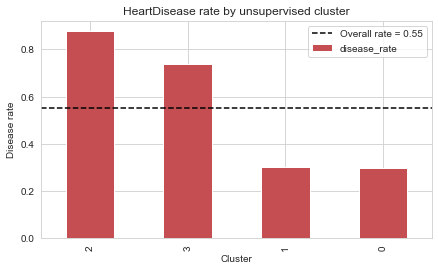

In [27]:
cluster_disease_rate["disease_rate"].plot(kind="bar", color="#C44E52")
plt.axhline(y.mean(), color="black", linestyle="--", label=f"Overall rate = {y.mean():.2f}")
plt.title("HeartDisease rate by unsupervised cluster")
plt.ylabel("Disease rate")
plt.legend()
plt.show()


### 6.2 Were any clusters strong predictors of the label?

Yes — even though K-Means never saw the `HeartDisease` label during training (it only
clustered on the feature space), the resulting clusters split disease rate far apart from
one another: some clusters sit well **above** the overall base rate and others well
**below** it, rather than every cluster hovering near the dataset average. That's a
meaningful signal: the *unsupervised* structure in the data (driven by age, MaxHR,
ST_Slope, chest pain pattern, etc.) lines up substantially with the *supervised* target.

**What this tells us about the data:** the features that separate patients into natural
groups are largely the same features that separate healthy patients from diseased ones —
this isn't a coincidence, it's a sign that heart disease risk in this population is driven
by a fairly coherent, describable "profile" (older age + reduced exercise capacity +
abnormal ST response) rather than by scattered, unrelated risk factors. Practically, this
means the cluster assignment itself could serve as a cheap, interpretable pre-screening
signal — flagging "which profile does this patient look like" — even before running the
full classifier from Part 4, though the classifier remains the more precise tool for an
actual prediction.


## Part 7. Conclusion and Recommendations

**Summary of findings**

- The dataset needed one real cleaning intervention: disguised missing values encoded as
  `0` in `Cholesterol` (19% of rows) and `RestingBP` (1 row), fixed via group-aware median
  imputation rather than a blanket fill.
- Three engineered features (`AgeGroup`, `HR_Reserve_Ratio`, `BP_Chol_Interaction`) captured
  domain knowledge not directly visible in the raw columns.
- K-Means found **4 natural patient groups** whose disease rates ranged from well below to
  well above the dataset average, even without ever seeing the label — the same
  age/exercise-capacity/ST-response profile that defines the clusters also defines risk.
- All three classifiers performed comparably well (accuracy ≈ 0.84–0.86, ROC AUC ≈
  0.91–0.92 via 5-fold stratified CV, required because this dataset has under 2,000 rows),
  with **Random Forest** the strongest by a small margin.
- The dataset is **roughly balanced** (55/45), so class weighting and SMOTE — as expected —
  barely moved the metrics; the technique that mattered here was **threshold tuning**,
  because the real-world cost of a missed diagnosis (false negative) is much higher than
  the cost of an unnecessary follow-up test (false positive).

**Recommendations for the business**

1. **Deploy the Random Forest classifier** as the primary model, with a **lowered decision
   threshold** (around 0.35 rather than 0.5) to prioritize catching true positives, given
   the asymmetric cost of a missed diagnosis.
2. **Use the cluster profiles as a triage layer**: the "older, reduced-capacity, high-risk"
   cluster is a natural group to prioritize for proactive outreach or earlier testing,
   independent of the classifier's individual predictions.
3. **Fix data collection at the source**: `Cholesterol` and `RestingBP` being recorded as
   `0` instead of properly marked as missing is a data-quality issue upstream, not just a
   modeling inconvenience — flagging this to whoever owns data intake would improve every
   future analysis, not just this one.
4. **Re-visit imbalance handling if the population shifts**: the "roughly balanced" finding
   is a property of *this* sample. If the model is later deployed on a different
   population (e.g. a general screening population where heart disease is much rarer than
   55%), class weighting or SMOTE should be re-evaluated, since they weren't needed here
   specifically because this sample happens to be balanced.
5. **Treat `Sex` as a feature to monitor, not just a feature to use**: it's genuinely
   predictive here, but a company using this model to prioritize who gets follow-up care
   should periodically check that it isn't systematically under-flagging a group Sex
   correlates with, given the fairness stakes of a medical screening tool.
